# Testing normalization function

In [13]:
import sys
sys.path.insert(0, "../")

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [15]:
# Set parameters for MOSH plots
z_slice_mosh = 25
bins_mosh = 85
dose_grid_half_mosh = 2.5
lattice_mosh = dose_grid_half_mosh*2/bins_mosh
source_transZ_mosh = -0.5
source_plane_mosh = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, dose_grid_half_mosh*2/bins_mosh)

In [16]:
# Common parameters
norm_point = (0.0, 0.3)
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [17]:
# Step 1: define ROI
# Simple ROI = cubical region centered @ 0.5 cm from edge of applicator, 0.2 cm to each side
# Units = cm
x0 = -0.1
x1 = 0.1
y0 = 0.40
y1 = 0.60
roi_side = 0.2

roi = np.array([x0, x1, y0, y1])

# Convert ROI definition to voxel space - MOSH
roi_vox_mosh = cm_to_voxel(roi, bins_mosh, lattice_mosh)
print(roi_vox_mosh)

[40 44 49 52]


In [18]:
# MOSH
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

Xm, Ym, energym, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=False, zero_source=True, std_dev=False)

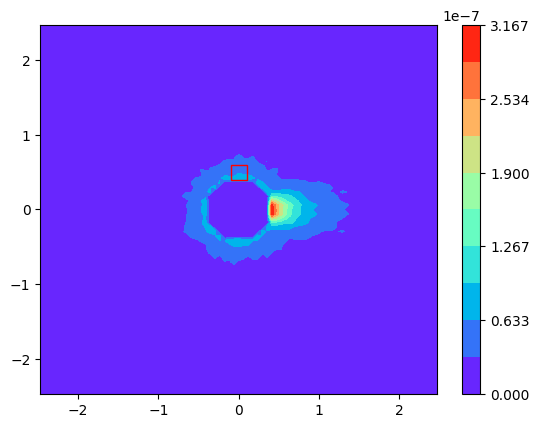

In [19]:
# Plot w/out normalization
fig0, ax0 = plt.subplots()
contour0 = ax0.contourf(Xm, Ym, energym, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
ax0.add_patch(region)

cbar0 = fig0.colorbar(contour0)

In [20]:
# Run normalization
dose = 12 # Gy
roi_cm = (0, 0.5)

normalized_energy = contour_normalization(energym, dose, roi_cm, bins_mosh, lattice_mosh)

2.487568622200342e-07
[42 50]


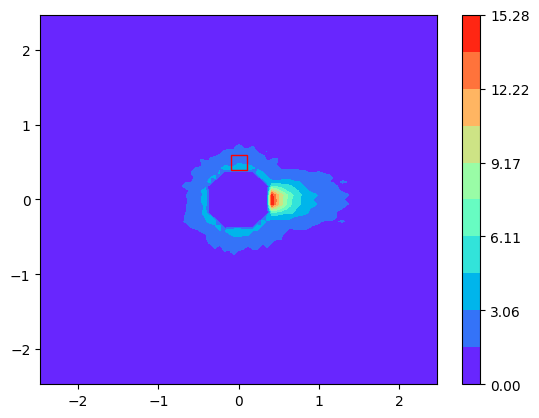

In [21]:
fig1, ax1 = plt.subplots()
contour1 = ax1.contourf(Xm, Ym, normalized_energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
ax1.add_patch(region)

cbar1 = fig1.colorbar(contour1)

In [22]:
# Test simpler normalization process - extract energy @ ROI point
norm_energy, norm_voxel = extract_norm_energy(mosh, source_plane_mosh, 2, roi_cm, bins_mosh, lattice_mosh)
print(norm_energy)
print(norm_voxel)

# We expect the norm energy here to be the same as above, but it's not - is there a problem with indexing between my function types somewhere?

2.487568622200342e-07
[42 50]


In [23]:
X0, Y0, energy0, __ = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane_mosh, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, dose=dose, zero_source=True, std_dev=False)

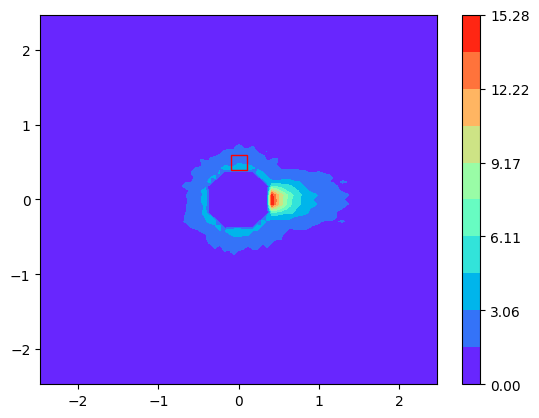

In [24]:
fig3, ax3 = plt.subplots()
contour3 = ax3.contourf(X0, Y0, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

region = patches.Rectangle((x0, y0), roi_side, roi_side, linewidth=1, edgecolor='r', facecolor='none')
ax3.add_patch(region)

cbar3 = fig3.colorbar(contour3)

Moving forward, we will use the simpler normalization that involves extracting energy at ROI + integrating normalization into the function contour_energy.